## TF-IDF

Baseline : TF-IDF (mots 1–2 + caractères 2–5) + régression logistique class_weight=&quot;balanced&quot; ; seuil de
décision choisi sur val (maximisation du F1 sarcastique).

import data:


In [1]:
import os
import time
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_curve,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# 1. Load data
ROOT = "./data/"
train = pd.read_csv(ROOT + "train.csv")
val = pd.read_csv(ROOT + "val.csv")
test = pd.read_csv(ROOT + "test.csv")

# Clean labels: 1 for True (sarcastic), 0 for False
y_train = train["sarcasm"].astype(int).values
y_val = val["sarcasm"].astype(int).values
y_test = test["sarcasm"].astype(int).values

# Ensure tweets are string type
X_train_raw = train["tweet"].fillna("").astype(str)
X_val_raw = val["tweet"].fillna("").astype(str)
X_test_raw = test["tweet"].fillna("").astype(str)

# 2. Trivial Classifier : "Jamais sarcastique" (all 0)
y_pred_trivial = np.zeros_like(y_val)
acc_triv = accuracy_score(y_val, y_pred_trivial)
f1_sarc_triv = f1_score(y_val, y_pred_trivial, pos_label=1, zero_division=0)

print("=" * 60)
print(f"BASELINE TRIVIALE ('jamais sarcastique') SUR VAL :")
print(f"Accuracy: {acc_triv:.4f} | F1-sarcastique: {f1_sarc_triv:.4f}")
print("Conclusion Q1 : L'accuracy est trompeuse (~82.7%) car la classe majoritaire domine.")
print("=" * 60)

BASELINE TRIVIALE ('jamais sarcastique') SUR VAL :
Accuracy: 0.8271 | F1-sarcastique: 0.0000
Conclusion Q1 : L'accuracy est trompeuse (~82.7%) car la classe majoritaire domine.


In [2]:
# Baseline spécifiée : Mots (1–2) + Caractères (2–5)
word_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    sublinear_tf=True
)
char_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5),
    sublinear_tf=True
)

tfidf = FeatureUnion([
    ("word", word_vectorizer),
    ("char", char_vectorizer)
])

print("Vectorisation TF-IDF en cours...")
t0 = time.time()
X_train_tfidf = tfidf.fit_transform(X_train_raw)
X_val_tfidf = tfidf.transform(X_val_raw)
X_test_tfidf = tfidf.transform(X_test_raw)
vectorization_time = time.time() - t0

print(f"TF-IDF terminé en {vectorization_time:.2f}s")
print(f"Dimensions X_train : {X_train_tfidf.shape}")
print(f"Vocabulaire mots       : {len(word_vectorizer.vocabulary_):,}")
print(f"Vocabulaire caractères : {len(char_vectorizer.vocabulary_):,}")
print(f"Total features         : {X_train_tfidf.shape[1]:,}")

Vectorisation TF-IDF en cours...
TF-IDF terminé en 7.13s
Dimensions X_train : (11293, 864961)
Vocabulaire mots       : 189,781
Vocabulaire caractères : 675,180
Total features         : 864,961


In [3]:
# Regression Logistique avec convergence garantie
log_reg = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42,
    solver="lbfgs",
    n_jobs=-1
)

t0 = time.time()
log_reg.fit(X_train_tfidf, y_train)
train_time = time.time() - t0
print(f"Entraînement terminé en {train_time:.2f}s")

c:\Users\pc\Desktop\M2 BDIO\LLMs\Project\TP_2 - Binome\Handwritten code\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Entraînement terminé en 2.16s


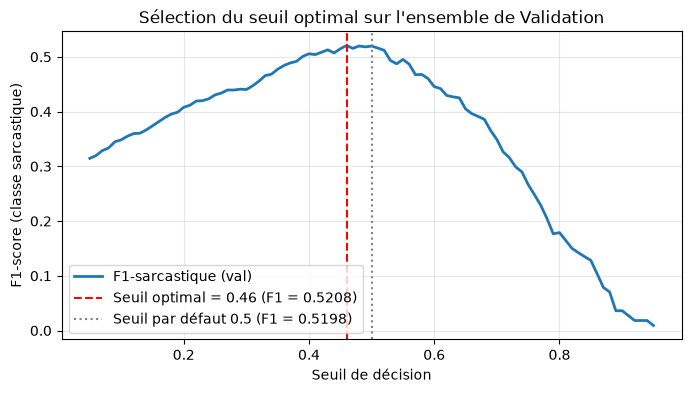

Seuil optimal choisi sur val : 0.46 (F1-sarc = 0.5208)


In [4]:
# Prédictions probabilistes sur val
val_probs = log_reg.predict_proba(X_val_tfidf)[:, 1]

# Balayage des seuils pour maximiser le F1 de la classe 1 (sarcastique)
thresholds = np.linspace(0.05, 0.95, 91)
f1_scores_val = []

for t in thresholds:
    preds = (val_probs >= t).astype(int)
    f1_scores_val.append(f1_score(y_val, preds, pos_label=1, zero_division=0))

best_idx = np.argmax(f1_scores_val)
best_threshold = thresholds[best_idx]
best_f1_val = f1_scores_val[best_idx]

# Visualisation F1 = f(seuil)
plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores_val, label="F1-sarcastique (val)", color="#1f77b4", lw=2)
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Seuil optimal = {best_threshold:.2f} (F1 = {best_f1_val:.4f})")
plt.axvline(0.5, color="gray", linestyle=":", label=f"Seuil par défaut 0.5 (F1 = {f1_scores_val[45]:.4f})")
plt.xlabel("Seuil de décision")
plt.ylabel("F1-score (classe sarcastique)")
plt.title("Sélection du seuil optimal sur l'ensemble de Validation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Seuil optimal choisi sur val : {best_threshold:.2f} (F1-sarc = {best_f1_val:.4f})")


In [5]:
def compute_metrics(y_true, probs, threshold):
    preds = (probs >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, preds),
        "f1_sarcastic": f1_score(y_true, preds, pos_label=1, zero_division=0),
        "f1_macro": f1_score(y_true, preds, average="macro", zero_division=0),
        "pr_auc": average_precision_score(y_true, probs),
        "precision_sarc": precision_score(y_true, preds, pos_label=1, zero_division=0),
        "recall_sarc": recall_score(y_true, preds, pos_label=1, zero_division=0)
    }

metrics_val = compute_metrics(y_val, val_probs, best_threshold)
print("=== RÉSULTATS VALIDATION (au seuil optimal) ===")
for k, v in metrics_val.items():
    print(f"{k:16s}: {v:.4f}")

# Évaluation sur Test (avec le seuil fixé sur val)
test_probs = log_reg.predict_proba(X_test_tfidf)[:, 1]
metrics_test = compute_metrics(y_test, test_probs, best_threshold)
print("\n=== RÉSULTATS TEST (au seuil choisi sur val) ===")
for k, v in metrics_test.items():
    print(f"{k:16s}: {v:.4f}")

print("\nRapport de classification (Test) :")
print(classification_report(y_test, (test_probs >= best_threshold).astype(int), target_names=["Non-sarcastique", "Sarcastique"]))


=== RÉSULTATS VALIDATION (au seuil optimal) ===
accuracy        : 0.7976
f1_sarcastic    : 0.5208
f1_macro        : 0.6962
pr_auc          : 0.5058
precision_sarc  : 0.4409
recall_sarc     : 0.6359

=== RÉSULTATS TEST (au seuil choisi sur val) ===
accuracy        : 0.6917
f1_sarcastic    : 0.5450
f1_macro        : 0.6559
pr_auc          : 0.5311
precision_sarc  : 0.4571
recall_sarc     : 0.6748

Rapport de classification (Test) :
                 precision    recall  f1-score   support

Non-sarcastique       0.85      0.70      0.77      2179
    Sarcastique       0.46      0.67      0.55       821

       accuracy                           0.69      3000
      macro avg       0.65      0.69      0.66      3000
   weighted avg       0.74      0.69      0.71      3000



In [6]:
# Audit demandé dans Partie A : URL, Mention, et Artefact de format (export CSV)
def detect_format_artefact(text):
    # Artefact CSV identifié en 4.1 : présence d'un guillemet initial/doublé ou entités HTML
    return bool(re.search(r'(^"|""|&quot;|&nbsp;)', text))

def audit_shortcut(df, condition_fn, name):
    mask = df["tweet"].fillna("").apply(condition_fn)
    total_with_feature = mask.sum()
    sarc_rate_with = df.loc[mask, "sarcasm"].astype(int).mean() if total_with_feature > 0 else 0
    sarc_rate_without = df.loc[~mask, "sarcasm"].astype(int).mean()
    
    # Classifieur à 1 seule règle : prédire sarcastique si la feature est présente
    preds = mask.astype(int)
    f1 = f1_score(df["sarcasm"].astype(int), preds, pos_label=1, zero_division=0)
    acc = accuracy_score(df["sarcasm"].astype(int), preds)
    prec = precision_score(df["sarcasm"].astype(int), preds, pos_label=1, zero_division=0)
    rec = recall_score(df["sarcasm"].astype(int), preds, pos_label=1, zero_division=0)
    
    return {
        "Indice": name,
        "Présence (count)": total_with_feature,
        "% sarc si présent": f"{sarc_rate_with*100:.1f}%",
        "% sarc si absent": f"{sarc_rate_without*100:.1f}%",
        "Règle F1-sarc": f"{f1:.4f}",
        "Règle Prec": f"{prec:.4f}",
        "Règle Rappel": f"{rec:.4f}",
        "Règle Acc": f"{acc:.4f}"
    }

shortcuts = [
    audit_shortcut(val, lambda t: bool(re.search(r'https?://\S+|t\.co/\S+', t)), "URL (http/t.co)"),
    audit_shortcut(val, lambda t: "@" in t, "Mention (@)"),
    audit_shortcut(val, detect_format_artefact, "Artefact CSV (guillemets ^\"/\"\")")
]

shortcuts_df = pd.DataFrame(shortcuts)
print("=== AUDIT DES RACCOURCIS SUR VAL (Partie A / Q2) ===")
display(shortcuts_df)


=== AUDIT DES RACCOURCIS SUR VAL (Partie A / Q2) ===


,Indice,Présence (count),% sarc si présent,% sarc si absent,Règle F1-sarc,Règle Prec,Règle Rappel,Règle Acc
0,URL (http/t.co),499,8.2%,23.3%,0.1145,0.0822,0.1889,0.4948
1,Mention (@),301,20.3%,16.4%,0.2355,0.2027,0.2811,0.6845
2,"Artefact CSV (guillemets ^""/"""")",781,14.5%,21.9%,0.2265,0.1447,0.5207,0.3849
